In [35]:
from langgraph.graph import StateGraph, START, END
from langchain_groq import ChatGroq
from typing import TypedDict
from dotenv import load_dotenv

load_dotenv()

True

In [36]:
model = ChatGroq(model="openai/gpt-oss-20b")

In [37]:
class BlogState(TypedDict):
    topic: str
    outline: str
    blog: str
    evaluate : int

In [38]:
def create_outline(state: BlogState) -> BlogState:
        topic = state['topic']

        # prompt = f"""Generate an outline for this Particular Topic
        # {topic}
        # """
        prompt = f"""You are an expert content strategist and professional copywriter. Your task is to generate a comprehensive, well-structured outline for a highly engaging blog post on the following topic.

        <topic>
        {topic}
        </topic>

        Please ensure the outline follows these strict guidelines:
        1. Structure: Include a Catchy Title, Introduction, Main Body (divided into logical H2 and H3 headings), and a Conclusion with a Call to Action (CTA).
        2. Depth: For every heading, provide 2-3 bullet points detailing the specific arguments, facts, or examples that should be covered in that section.
        3. Logical Flow: Ensure a smooth progression of ideas that hooks the reader and comprehensively answers the user's intent regarding the topic.

        Format your output entirely in clean Markdown.
        """


        outline = model.invoke(prompt).content

        state['outline'] = outline
    
        return state

In [39]:
def create_blog(state: BlogState) -> BlogState:
        topic = state['topic']
        
        outline = state['outline']

        # prompt = f"""Generate a Comprehensive Blog on the topic {topic} Using the following Outline
        # {outline}
        # """
        prompt = f"""You are an expert SEO content writer and industry authority. Your task is to write a highly engaging, comprehensive, and well-researched blog post about the following topic.

        <topic>
        {topic}
        </topic>

        You MUST strictly adhere to the structural outline provided below:

        <outline>
        {outline}
        </outline>

        Please follow these writing guidelines carefully:
        1. Tone and Voice: Write in a conversational yet authoritative tone. Keep the language engaging, accessible, but highly informative.
        2. Exact Structure: Follow the provided outline section by section. Use proper Markdown formatting for all headings (H1 for the main title, H2 and H3 for sub-sections).
        3. Depth and Detail: Do not just summarize the outline. Expand significantly on each point. Provide context, actionable advice, real-world examples, and deep explanations.
        4. Readability: Use short paragraphs, bullet points, numbered lists, and **bold text** where appropriate to break up large chunks of text and make the post scannable.
        5. Transitions: Ensure smooth, logical transitions between paragraphs and headings so the article flows naturally from the introduction to the conclusion.

        Do not include any pleasantries or conversational filler (e.g., "Here is your blog post..."). Output ONLY the final, complete blog post formatted in Markdown.
        """

        Blog = model.invoke(prompt).content

        state['blog'] = Blog
    
        return state

In [40]:
def Evaluate(state: BlogState) -> BlogState:
        outline = state['outline']

        blog = state['blog']

        # prompt = f"""Based on this outline {outline} rate my blog {blog} and generate a score in integer. 
        # """
        prompt = f"""You are an expert content evaluator. Your task is to score how well a blog post follows its provided outline. 

        Evaluate the alignment based on topic coverage, structural flow, and relevance. 
        Score the alignment on a scale of 1 to 100, where 100 means the blog perfectly matches the outline, and 1 means it completely deviates.

        Return ONLY the integer score. Do not output any other text, reasoning, punctuation, or formatting.

        Outline:
        ---
        {outline}
        ---

        Blog Post:
        ---
        {blog}
        ---
        """

        
        evaluate = model.invoke(prompt).content

        state['evaluate'] = evaluate
    
        return state

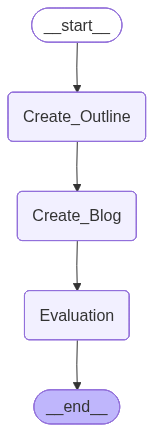

In [41]:
graph = StateGraph(BlogState)
#node
graph.add_node('Create_Outline', create_outline)

graph.add_node('Create_Blog', create_blog)

graph.add_node('Evaluation', Evaluate)

graph.add_edge(START, 'Create_Outline')

graph.add_edge('Create_Outline', 'Create_Blog')

graph.add_edge('Create_Blog', 'Evaluation')

graph.add_edge('Evaluation', END)

PC_workflow = graph.compile()

PC_workflow

In [42]:
input_state = {'topic': "ML"}

final_state = PC_workflow.invoke(input_state)

print(final_state)

{'topic': 'ML', 'outline': '## 🔍 **From Data to Decisions: Unlocking the Power of Machine Learning Today**\n\n---\n\n### **Introduction**\n- **Hook:** Picture a world where your phone predicts the next song you’ll love *before* you even think about it.\n- **Why ML matters:** Briefly explain how ML is transforming everyday life—from personalized recommendations to autonomous vehicles.\n- **What you’ll learn:** Outline the journey of the post: definition, relevance, core concepts, real‑world use cases, a hands‑on starter guide, ethical considerations, and future outlook.\n\n---\n\n## **Main Body**\n\n### **H2: 1️⃣ What Is Machine Learning?**\n- **Definition & Scope**\n  - Distinguish ML from traditional programming and AI.\n  - Explain the role of data, models, and learning algorithms.\n- **Types of ML**\n  - Supervised, unsupervised, and reinforcement learning with simple examples.\n- **Key Terminology**\n  - Model, training, inference, features, labels, loss function.\n\n#### **H3: 1.1

In [43]:
print(final_state['topic'])

ML


In [32]:
print(final_state['outline'])

**Outline: Machine Learning (ML)**  
*(A comprehensive, modular framework suitable for a textbook, course syllabus, or research survey)*  

---

### 1. Introduction  
1.1. What is Machine Learning?  
1.2. ML vs. Traditional Programming  
1.3. Historical Milestones (1950s‑present)  
1.4. Interdisciplinary Roots (statistics, computer science, neuroscience, cognitive science)  
1.5. Applications & Impact (industry, academia, everyday life)

---

### 2. Foundations of Machine Learning  
2.1. Problem Formulation  
&nbsp;&nbsp;&nbsp;&nbsp;2.1.1. Input–Output Mapping  
&nbsp;&nbsp;&nbsp;&nbsp;2.1.2. Loss Functions & Optimization Goals  
2.2. Data: Types, Quality, and Preprocessing  
&nbsp;&nbsp;&nbsp;&nbsp;2.2.1. Structured vs. Unstructured Data  
&nbsp;&nbsp;&nbsp;&nbsp;2.2.2. Feature Engineering & Representation Learning  
&nbsp;&nbsp;&nbsp;&nbsp;2.2.3. Data Augmentation & Imputation  
2.3. Statistical Learning Theory  
&nbsp;&nbsp;&nbsp;&nbsp;2.3.1. Bias–Variance Trade‑off  
&nbsp;&nbsp;&n

In [44]:
print(final_state['blog'])

# 🔍 **From Data to Decisions: Unlocking the Power of Machine Learning Today**

---

## **Introduction**

Picture a world where your phone predicts the next song you’ll love *before* you even think about it.  
This isn’t a sci‑fi fantasy—it’s the reality of modern machine learning (ML). From the personalized playlists that keep us humming, to self‑driving cars that navigate city streets, ML is quietly steering our daily lives.

- **Why ML matters:** It turns raw data into actionable insights, powering everything from health diagnostics to financial forecasting.
- **What you’ll learn:** We’ll unpack what ML really is, why it’s essential in 2024, dive into core concepts and algorithms, explore real‑world applications, walk through a hands‑on project, and discuss ethics, bias, and the future of ML.

---

## **Main Body**

### **1️⃣ What Is Machine Learning?**

#### **Definition & Scope**

- **Machine Learning vs. Traditional Programming:** Traditional code tells a computer *how* to perform

In [45]:
print(final_state['evaluate'])

65
